# Sensor placement: corrected and confirmatory evaluation

This notebook is the **authoritative evaluation**. It fixes the issues found in the audit of
`sensor_placement.ipynb` (that notebook is kept unchanged as the record of the development runs).

## Frozen protocol (decided before looking at any 2024 data)

| Item | Setting |
|---|---|
| Ground truth | USDA SCAN, `SMS:-2:1` (≈5 cm), monthly mean, continental US |
| Quality control | ≥ 20 valid days in the month; monthly mean ≥ 1.0 % (lower = implausible / dead sensor); every exclusion logged |
| Coarse prior | ERA5-Land `soil_moisture_0_to_7cm` via Open-Meteo, `models=era5_land` **required** (no fallback) |
| Model | `station = a + b·ERA5 + GP residual`, Matérn 3/2 on lon/lat + white noise |
| Prediction | universal kriging: a, b fitted by **GLS** on the chosen sensors, jointly with the GP |
| Kernel + residual scale | learned on the **same month of the previous year**, then fixed (residual scale too, not re-estimated from the few chosen sensors) |
| Methods | random (no prior), random + prior, k-means (space), k-means (space + wetness), MI + prior, calibration-aware MI + prior |
| Calibration-aware MI | universal-kriging variance given the chosen sensors ÷ universal-kriging variance given the other candidates (both sides consistent) |
| Splits | 50 runs per month; 40 held-out test stations; the rest are candidates; budgets 5, 10, 20, 30; 2 random seed sensors for greedy methods |
| Runs | **Development**: 2023 months, kernel from 2022 (the data the method was designed on). **Confirmatory**: Apr/Jun/Aug/Oct **2024**, kernel from 2023 — data never used for any design choice |
| Statistics | mean paired MAE improvement with 95 % CI from the corrected resampled t-test (Nadeau & Bengio, 2003), which accounts for overlapping random splits; Holm correction over all 20 comparisons; number of months (of 4) where the method is better |
| Determinism | all randomness seeded (`random_state=0` for GP restarts; run index for splits) |

**What changed vs `sensor_placement.ipynb` §16, and why**
1. GP optimiser restarts were unseeded → results changed slightly between runs (7.60 vs 7.58). Now seeded.
2. ERA5 requests silently fell back to Open-Meteo's default model on an error. Now they fail.
3. The criterion mixed a universal-kriging numerator with an ordinary-GP denominator, and the predictor
   fitted the calibration line by OLS while the variance assumed GLS. Now both use universal kriging.
4. The residual scale was re-estimated from the 5–30 chosen sensors (noisy). Now it comes from the
   historical month, like the kernel.
5. Sign-test p-values treated 200 overlapping runs as independent. Now corrected CIs + Holm.
6. Method choices were made while looking at 2023 results. The 2024 run is the clean, confirmatory test.

Runtime ≈ 30–40 min. No NASA login needed.

In [4]:
import json, os, time, datetime, platform, zipfile
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import sklearn
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel
from sklearn.cluster import KMeans
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

STATIONS_URL = "https://wcc.sc.egov.usda.gov/awdbRestApi/services/v1/stations"
DATA_URL = "https://wcc.sc.egov.usda.gov/awdbRestApi/services/v1/data"
OM_URL = "https://archive-api.open-meteo.com/v1/archive"
ELEMENT = "SMS:-2:1"

MIN_DAYS = 20          # QC: valid days per month
MIN_MOISTURE = 1.0     # QC: monthly mean below this (%) is treated as a dead / implausible sensor
N_TEST = 40
RUNS = 50
COUNTS = [5, 10, 20, 30]
N_SEED = 2
JITTER = 1e-8
GP_SEED = 0

RUN_INFO = {
    "run_started_utc": datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z",
    "python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__, "scipy": scipy.__version__,
    "protocol": {"min_days": MIN_DAYS, "min_moisture_pct": MIN_MOISTURE, "n_test": N_TEST, "runs": RUNS,
                 "counts": COUNTS, "n_seed": N_SEED, "gp_seed": GP_SEED, "element": ELEMENT,
                 "coarse_prior": "ERA5-Land soil_moisture_0_to_7cm via Open-Meteo (models=era5_land, no fallback)"},
    "months": {},
}
print(json.dumps({k: RUN_INFO[k] for k in ["python", "numpy", "scikit_learn", "scipy"]}, indent=1))

{
 "python": "3.13.16",
 "numpy": "2.1.3",
 "scikit_learn": "1.6.1",
 "scipy": "1.16.3"
}


/tmp/ipykernel_1229/3889304560.py:31: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "run_started_utc": datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z",


## 1. Stations and data (with QC log and raw snapshots)

In [5]:
r = requests.get(STATIONS_URL, params={"activeOnly": "true"}, timeout=60)
r.raise_for_status()
st = pd.DataFrame(r.json())
scan = st[st.networkCode == "SCAN"][["stationTriplet", "name", "stateCode", "latitude", "longitude"]]
mainland = scan[(scan.latitude > 25) & (scan.latitude < 50) &
                (scan.longitude > -125) & (scan.longitude < -66)].reset_index(drop=True)
all_ids = list(mainland.stationTriplet)
RUN_INFO["stations_listed"] = {"scan_active": int(len(scan)), "mainland": int(len(mainland))}
print("SCAN active:", len(scan), "| continental US:", len(mainland))


def fetch_ground(begin, end):
    """Monthly-mean SCAN soil moisture with logged QC exclusions."""
    params = {"stationTriplets": ",".join(all_ids), "elements": ELEMENT,
              "duration": "DAILY", "beginDate": begin, "endDate": end}
    r = requests.get(DATA_URL, params=params, timeout=300)
    r.raise_for_status()
    rows = []
    excluded = []
    for s in r.json():
        series = s.get("data", [])
        if not series:
            continue
        values = [v["value"] for v in series[0]["values"] if v.get("value") is not None]
        if len(values) < MIN_DAYS:
            excluded.append({"stationTriplet": s["stationTriplet"], "reason": f"only {len(values)} valid days"})
            continue
        mean = sum(values) / len(values)
        if mean < MIN_MOISTURE:
            excluded.append({"stationTriplet": s["stationTriplet"], "reason": f"monthly mean {mean:.2f}% < {MIN_MOISTURE}%"})
            continue
        rows.append({"stationTriplet": s["stationTriplet"], "moisture": mean, "n_days": len(values)})
    df = mainland.merge(pd.DataFrame(rows), on="stationTriplet", how="inner")
    return df, excluded


def fetch_era5(lats, lons, begin, end, batch=25):
    """Monthly-mean ERA5-Land soil moisture (%). Raises instead of silently switching model."""
    out = []
    for start in range(0, len(lats), batch):
        params = {"latitude": ",".join(f"{v:.4f}" for v in lats[start:start + batch]),
                  "longitude": ",".join(f"{v:.4f}" for v in lons[start:start + batch]),
                  "start_date": begin, "end_date": end,
                  "hourly": "soil_moisture_0_to_7cm", "models": "era5_land"}
        for attempt in range(5):
            r = requests.get(OM_URL, params=params, timeout=120)
            if r.status_code == 429:
                print("  rate limited, waiting 60 s...")
                time.sleep(60)
                continue
            break
        if r.status_code != 200:
            raise RuntimeError(f"Open-Meteo ERA5-Land request failed ({r.status_code}): {r.text[:300]}")
        js = r.json()
        if isinstance(js, dict):
            js = [js]
        for loc in js:
            if "hourly" not in loc or "soil_moisture_0_to_7cm" not in loc["hourly"]:
                raise RuntimeError("Open-Meteo response has no soil_moisture_0_to_7cm - refusing to continue")
            vals = [v for v in loc["hourly"]["soil_moisture_0_to_7cm"] if v is not None]
            out.append(100.0 * sum(vals) / len(vals) if vals else np.nan)
        time.sleep(3)
    return np.array(out)


os.makedirs("snapshots", exist_ok=True)


def load_month(begin, end, tag):
    df, excluded = fetch_ground(begin, end)
    df["era5"] = fetch_era5(list(df.latitude), list(df.longitude), begin, end)
    no_era5 = df[df.era5.isna()]
    for t in no_era5.stationTriplet:
        excluded.append({"stationTriplet": t, "reason": "no ERA5-Land value (water cell)"})
    df = df[df.era5.notna()].reset_index(drop=True)
    df.to_csv(f"snapshots/{tag}.csv", index=False)
    RUN_INFO["months"][tag] = {"begin": begin, "end": end, "stations_used": int(len(df)),
                               "excluded": excluded,
                               "retrieved_utc": datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z"}
    print(f"{tag}: {len(df)} stations used, {len(excluded)} excluded")
    return df


MONTH_DAYS = {"04": "30", "06": "30", "08": "31", "10": "31"}
data = {}
for year in ["2022", "2023", "2024"]:
    for m in ["04", "06", "08", "10"]:
        tag = f"{year}-{m}"
        data[tag] = load_month(f"{year}-{m}-01", f"{year}-{m}-{MONTH_DAYS[m]}", tag)

SCAN active: 210 | continental US: 193


/tmp/ipykernel_1229/2080229941.py:79: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "retrieved_utc": datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z"}


2022-04: 161 stations used, 9 excluded


/tmp/ipykernel_1229/2080229941.py:79: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "retrieved_utc": datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z"}


2022-06: 157 stations used, 12 excluded


...

/tmp/ipykernel_1229/2080229941.py:79: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "retrieved_utc": datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z"}


2023-04: 160 stations used, 10 excluded


/tmp/ipykernel_1229/2080229941.py:79: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "retrieved_utc": datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z"}


2023-06: 162 stations used, 7 excluded


ConnectionError: HTTPSConnectionPool(host='wcc.sc.egov.usda.gov', port=443): Max retries exceeded with url: /awdbRestApi/services/v1/data?stationTriplets=2057%3AAL%3ASCAN%2C2092%3AKS%3ASCAN%2C2015%3ANM%3ASCAN%2C2235%3ACA%3ASCAN%2C2237%3ACA%3ASCAN%2C2172%3ANM%3ASCAN%2C2138%3AUT%3ASCAN%2C2076%3ATN%3ASCAN%2C2031%3AIA%3ASCAN%2C2214%3ACA%3ASCAN%2C2032%3AMS%3ASCAN%2C2207%3ATX%3ASCAN%2C2135%3AUT%3ASCAN%2C2215%3ACA%3ASCAN%2C2078%3AAL%3ASCAN%2C2177%3AAL%3ASCAN%2C2216%3ANV%3ASCAN%2C2151%3AUT%3ASCAN%2C2224%3AMO%3ASCAN%2C2006%3ATX%3ASCAN%2C2136%3AUT%3ASCAN%2C2223%3AMO%3ASCAN%2C2161%3AUT%3ASCAN%2C2094%3AKS%3ASCAN%2C2145%3ANV%3ASCAN%2C2150%3AUT%3ASCAN%2C2240%3ACA%3ASCAN%2C2125%3AUT%3ASCAN%2C2195%3AMO%3ASCAN%2C2189%3ACA%3ASCAN%2C2117%3AMT%3ASCAN%2C2198%3AWA%3ASCAN%2C2197%3ACO%3ASCAN%2C2002%3AMN%3ASCAN%2C2107%3ANM%3ASCAN%2C2113%3AAL%3ASCAN%2C2190%3ACA%3ASCAN%2C2174%3AAL%3ASCAN%2C2187%3ACA%3ASCAN%2C2183%3ACA%3ASCAN%2C2048%3AMO%3ASCAN%2C2191%3ACA%3ASCAN%2C2192%3ACA%3ASCAN%2C2130%3AUT%3ASCAN%2C2077%3ATN%

In [6]:
for year in ["2022", "2023", "2024"]:
    for m in ["04", "06", "08", "10"]:
        tag = f"{year}-{m}"
        if tag in data:
            continue
        for attempt in range(5):
            try:
                data[tag] = load_month(f"{year}-{m}-01", f"{year}-{m}-{MONTH_DAYS[m]}", tag)
                break
            except requests.exceptions.ConnectionError as e:
                print(f"  {tag}: connection problem, retrying in 30 s ({attempt + 1}/5)")
                time.sleep(30)
print("months loaded:", len(data), "of 12")

/tmp/ipykernel_1229/2080229941.py:79: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "retrieved_utc": datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z"}


2023-08: 164 stations used, 7 excluded


/tmp/ipykernel_1229/2080229941.py:79: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "retrieved_utc": datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z"}


2023-10: 159 stations used, 15 excluded


/tmp/ipykernel_1229/2080229941.py:79: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "retrieved_utc": datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z"}


...

/tmp/ipykernel_1229/2080229941.py:79: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "retrieved_utc": datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z"}


2024-06: 170 stations used, 12 excluded
  2024-08: connection problem, retrying in 30 s (1/5)


/tmp/ipykernel_1229/2080229941.py:79: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "retrieved_utc": datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z"}


2024-08: 169 stations used, 14 excluded
2024-10: 163 stations used, 28 excluded
months loaded: 12 of 12


/tmp/ipykernel_1229/2080229941.py:79: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "retrieved_utc": datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z"}


## 2. Model and placement criteria

Notation: K = kernel matrix of the chosen sensors (with noise), F = rows [1, ERA5/10], everything in units
of the historical residual scale S.

- **Universal kriging predictor:** β = (FᵀK⁻¹F)⁻¹FᵀK⁻¹y (GLS), ŷ(x) = f(x)ᵀβ + k(x)ᵀK⁻¹(y − Fβ).
- **Universal kriging variance** σ²_UK(x | A) = GP variance + calibration-line uncertainty.
- **Leave-one-out UK variance over candidates:** 1 / Q_xx with Q = K⁻¹ − K⁻¹F(FᵀK⁻¹F)⁻¹FᵀK⁻¹
  (checked against brute force in the cell below).
- **Calibration-aware MI:** σ²_UK(x | chosen) / σ²_UK(x | other candidates).
- **MI (baseline):** the same ratio with ordinary GP variances (ignores the calibration line).

In [7]:
def features(df):
    return df[["longitude", "latitude"]].values


def design(prior):
    return np.column_stack([np.ones(len(prior)), np.asarray(prior) / 10.0])


def learn_kernel(X, target):
    """Kernel learned on standardised targets; returns the kernel and the scale S."""
    s = float(target.std())
    z = (target - target.mean()) / s
    k = ConstantKernel(1.0) * Matern(length_scale=5.0, nu=1.5) + WhiteKernel(noise_level=0.1)
    gp = GaussianProcessRegressor(kernel=k, n_restarts_optimizer=3, normalize_y=False, random_state=GP_SEED)
    gp.fit(X, z)
    return gp.kernel_, s


def ols(xv, yv):
    xm = xv.mean()
    ym = yv.mean()
    sxx = np.sum((xv - xm) ** 2)
    b = np.sum((xv - xm) * (yv - ym)) / sxx if sxx > 0 else 1.0
    return ym - b * xm, b


def uk_predict(kernel, S, X, y, F, chosen, test):
    """Universal kriging (GLS trend + GP), in units of S."""
    XA = X[chosen]
    FA = F[chosen]
    yA = y[chosen] / S
    K = kernel(XA) + JITTER * np.eye(len(chosen))
    Ki = np.linalg.inv(K)
    M = FA.T @ Ki @ FA + 1e-8 * np.eye(F.shape[1])
    beta = np.linalg.solve(M, FA.T @ Ki @ yA)
    kt = kernel(X[test], XA)
    pred = F[test] @ beta + kt @ (Ki @ (yA - FA @ beta))
    return pred * S


def mae(kernel, S, X, y, F, chosen, test):
    return float(np.mean(np.abs(uk_predict(kernel, S, X, y, F, chosen, test) - y[test])))


def gp_var(kernel, Xq, XA):
    K = kernel(XA) + JITTER * np.eye(len(XA))
    Kq = kernel(Xq, XA)
    v = np.linalg.solve(K, Kq.T)
    return np.maximum(kernel.diag(Xq) - np.sum(Kq * v.T, axis=1), 1e-12)


def uk_var(kernel, Xq, XA, Fq, FA):
    K = kernel(XA) + JITTER * np.eye(len(XA))
    Kq = kernel(Xq, XA)
    A = np.linalg.solve(K, Kq.T)
    g = kernel.diag(Xq) - np.sum(Kq * A.T, axis=1)
    M = FA.T @ np.linalg.solve(K, FA) + 1e-8 * np.eye(FA.shape[1])
    R = Fq - A.T @ FA
    return np.maximum(g + np.sum((R @ np.linalg.inv(M)) * R, axis=1), 1e-12)


def gp_loo(kernel, Xc):
    Ki = np.linalg.inv(kernel(Xc) + JITTER * np.eye(len(Xc)))
    return np.maximum(1.0 / np.diag(Ki), 1e-12)


def uk_loo(kernel, Xc, Fc):
    Ki = np.linalg.inv(kernel(Xc) + JITTER * np.eye(len(Xc)))
    M = Fc.T @ Ki @ Fc + 1e-8 * np.eye(Fc.shape[1])
    Q = Ki - Ki @ Fc @ np.linalg.inv(M) @ Fc.T @ Ki
    return np.maximum(1.0 / np.diag(Q), 1e-12)


def greedy(kernel, X, F, pool, n, seed, criterion):
    rng = np.random.default_rng(seed)
    idx = np.array(pool)
    rng.shuffle(idx)
    known = list(idx[:N_SEED])
    cand = list(idx[N_SEED:])
    while len(known) < n and len(cand) > 0:
        Xc = X[cand]
        Fc = F[cand]
        if criterion == "calib_mi":
            score = uk_var(kernel, Xc, X[known], Fc, F[known]) / uk_loo(kernel, Xc, Fc)
        else:
            score = gp_var(kernel, Xc, X[known]) / gp_loo(kernel, Xc)
        best = int(np.argmax(score))
        known.append(cand[best])
        cand.pop(best)
    return known


def kmeans_pick(feats, pool, n, seed):
    Fp = feats[pool]
    km = KMeans(n_clusters=n, n_init=10, random_state=seed).fit(Fp)
    chosen = []
    for c in range(n):
        centre = km.cluster_centers_[c]
        best = None
        best_d = 1e18
        for j in range(len(pool)):
            if pool[j] in chosen:
                continue
            d = np.sum((Fp[j] - centre) ** 2)
            if d < best_d:
                best_d = d
                best = pool[j]
        chosen.append(best)
    return chosen


# --- self-check: fast UK leave-one-out = brute force ---
_r = np.random.default_rng(1)
_X = _r.uniform(0, 10, (25, 2))
_F = design(_r.uniform(5, 40, 25))
_k = ConstantKernel(0.6) * Matern(1.5, nu=1.5) + WhiteKernel(0.5)
_fast = uk_loo(_k, _X, _F)
_brute = np.array([uk_var(_k, _X[i:i + 1], np.delete(_X, i, 0), _F[i:i + 1], np.delete(_F, i, 0))[0] for i in range(25)])
assert np.allclose(_fast, _brute, rtol=1e-6), "UK leave-one-out formula check failed"
print("UK leave-one-out formula check: OK (max rel diff %.1e)" % np.max(np.abs(_fast - _brute) / _brute))

UK leave-one-out formula check: OK (max rel diff 1.3e-08)


## 3. The experiment

In [9]:
METHODS = ["random, no prior", "random + prior", "k-means (space) + prior",
           "k-means (space+wetness) + prior", "MI + prior", "calib-MI + prior"]


def historical_kernels(hist_df):
    X = features(hist_df)
    y = hist_df["moisture"].values
    p = hist_df["era5"].values
    a, b = ols(p, y)
    k_resid, s_resid = learn_kernel(X, y - (a + b * p))
    k_plain, s_plain = learn_kernel(X, y)
    return {"resid": k_resid, "s_resid": s_resid, "plain": k_plain, "s_plain": s_plain, "n": len(hist_df)}


def run_month(df, hk, label):
    X = features(df)
    y = df["moisture"].values
    p = df["era5"].values
    F = design(p)
    F1 = np.ones((len(df), 1))
    geo = np.column_stack([df.longitude.values, df.latitude.values])
    errs = {}
    for n in COUNTS:
        errs[n] = {}
        for m in METHODS:
            errs[n][m] = []
    n_pool = []
    split_log = []
    for run in range(RUNS):
        rng = np.random.default_rng(run)
        order = rng.permutation(len(df))
        test = list(order[:N_TEST])
        pool = list(order[N_TEST:])
        assert len(set(test) & set(pool)) == 0
        n_pool.append(len(pool))
        split_log.append([df.stationTriplet.iloc[i] for i in test])
        gw = np.column_stack([df.longitude.values, df.latitude.values, p])
        gw = (gw - gw[pool].mean(axis=0)) / gw[pool].std(axis=0)
        for n in COUNTS:
            pick = list(rng.choice(pool, n, replace=False))
            km1 = kmeans_pick(geo, pool, n, run)
            km2 = kmeans_pick(gw, pool, n, run)
            mi = greedy(hk["resid"], X, F, pool, n, run, "mi")
            cm = greedy(hk["resid"], X, F, pool, n, run, "calib_mi")
            for chosen in [pick, km1, km2, mi, cm]:
                assert len(set(chosen) & set(test)) == 0, "a method picked a test station"
            errs[n]["random, no prior"].append(mae(hk["plain"], hk["s_plain"], X, y, F1, pick, test))
            errs[n]["random + prior"].append(mae(hk["resid"], hk["s_resid"], X, y, F, pick, test))
            errs[n]["k-means (space) + prior"].append(mae(hk["resid"], hk["s_resid"], X, y, F, km1, test))
            errs[n]["k-means (space+wetness) + prior"].append(mae(hk["resid"], hk["s_resid"], X, y, F, km2, test))
            errs[n]["MI + prior"].append(mae(hk["resid"], hk["s_resid"], X, y, F, mi, test))
            errs[n]["calib-MI + prior"].append(mae(hk["resid"], hk["s_resid"], X, y, F, cm, test))
    print(f"=== {label} ({len(df)} stations, kernel from {hk['n']} historical stations)")
    for n in COUNTS:
        print(f"n={n:3d}  " + "  ".join(f"{m} {np.mean(errs[n][m]):.2f}" for m in METHODS))
    print()
    return {"errs": errs, "n_pool": int(np.mean(n_pool)), "test_sets": split_log}


def run_protocol(eval_year, hist_year):
    out = {}
    for m in ["04", "06", "08", "10"]:
        hk = historical_kernels(data[f"{hist_year}-{m}"])
        out[f"{eval_year}-{m}"] = run_month(data[f"{eval_year}-{m}"], hk, f"{eval_year}-{m}")
        out[f"{eval_year}-{m}"]["kernel"] = {"resid": str(hk["resid"]), "s_resid": hk["s_resid"],
                                             "plain": str(hk["plain"]), "s_plain": hk["s_plain"]}
        out[f"{eval_year}-{m}"]["hk"] = hk
    return out

## 4. Statistics

For each comparison (proposed vs a baseline) and budget: d = baseline MAE − method MAE per run
(positive = proposed is better). Within a month, the 50 runs share stations, so the variance of the mean is
inflated by the corrected resampled t-test factor (1/J + n_test/n_train) (Nadeau & Bengio, 2003). The four
monthly means are combined (assuming months are independent — they share stations, so this is stated as a
limitation), giving a 95 % CI and a p-value; p-values are Holm-adjusted over all 20 comparisons.
"Months better" counts in how many of the 4 months the mean improvement is positive.

In [10]:
COMPARISONS = [("calib-MI + prior", "random, no prior"),
               ("calib-MI + prior", "random + prior"),
               ("calib-MI + prior", "k-means (space) + prior"),
               ("calib-MI + prior", "k-means (space+wetness) + prior"),
               ("calib-MI + prior", "MI + prior")]


def holm(pvals):
    order = np.argsort(pvals)
    adj = np.zeros(len(pvals))
    running = 0.0
    for rank in range(len(order)):
        i = order[rank]
        val = min(1.0, (len(pvals) - rank) * pvals[i])
        running = max(running, val)
        adj[i] = running
    return adj


def analyse(results, title):
    months = list(results)
    rows = []
    for meth, base in COMPARISONS:
        for n in COUNTS:
            means = []
            ses = []
            base_means = []
            for mo in months:
                e_m = np.array(results[mo]["errs"][n][meth])
                e_b = np.array(results[mo]["errs"][n][base])
                d = e_b - e_m
                J = len(d)
                corr = 1.0 / J + N_TEST / results[mo]["n_pool"]
                means.append(d.mean())
                ses.append(np.sqrt(corr * d.var(ddof=1)))
                base_means.append(e_b.mean())
            dbar = float(np.mean(means))
            se = float(np.sqrt(np.sum(np.square(ses))) / len(months))
            z = dbar / se if se > 0 else 0.0
            p = float(2 * stats.norm.sf(abs(z)))
            rows.append({"method": meth, "baseline": base, "n": n,
                         "baseline_mae": float(np.mean(base_means)), "delta_mae": dbar,
                         "pct": 100 * dbar / float(np.mean(base_means)),
                         "ci_low": dbar - 1.96 * se, "ci_high": dbar + 1.96 * se,
                         "p": p, "months_better": int(np.sum(np.array(means) > 0))})
    adj = holm(np.array([r["p"] for r in rows]))
    for i in range(len(rows)):
        rows[i]["p_holm"] = float(adj[i])

    mae_table = {}
    for n in COUNTS:
        mae_table[str(n)] = {}
        for m in METHODS:
            mae_table[str(n)][m] = round(float(np.mean([np.mean(results[mo]["errs"][n][m]) for mo in months])), 2)

    print(f"##### {title}")
    print("Mean MAE (% soil moisture) over 4 months x 50 runs:")
    print(pd.DataFrame(mae_table).T.to_string())
    print()
    print("Calibration-aware MI + prior vs each baseline (positive = proposed better):")
    show = pd.DataFrame([{"vs": r["baseline"], "n": r["n"],
                          "dMAE": f"{r['delta_mae']:+.2f}", "%": f"{r['pct']:+.1f}%",
                          "95% CI": f"[{r['ci_low']:+.2f}, {r['ci_high']:+.2f}]",
                          "p (Holm)": f"{r['p_holm']:.4f}", "months better": f"{r['months_better']}/4"} for r in rows])
    print(show.to_string(index=False))
    print()
    return {"mae": mae_table, "comparisons": rows}

## 5. Development run — 2023 (kernel from 2022)

This is the data the method was designed on, rerun with the corrected code. Report it as development
results, not as the main evidence.

In [11]:
dev = run_protocol("2023", "2022")
dev_stats = analyse(dev, "DEVELOPMENT: 2023 evaluation, kernel from 2022")

=== 2023-04 (160 stations, kernel from 161 historical stations)
n=  5  random, no prior 10.27  random + prior 11.34  k-means (space) + prior 10.32  k-means (space+wetness) + prior 9.35  MI + prior 9.46  calib-MI + prior 9.24
n= 10  random, no prior 9.38  random + prior 9.04  k-means (space) + prior 8.37  k-means (space+wetness) + prior 8.66  MI + prior 8.96  calib-MI + prior 8.74
n= 20  random, no prior 9.04  random + prior 8.48  k-means (space) + prior 8.36  k-means (space+wetness) + prior 8.31  MI + prior 8.23  calib-MI + prior 8.34
n= 30  random, no prior 8.66  random + prior 8.16  k-means (space) + prior 8.34  k-means (space+wetness) + prior 8.21  MI + prior 8.10  calib-MI + prior 8.05

=== 2023-06 (162 stations, kernel from 157 historical stations)
n=  5  random, no prior 7.76  random + prior 8.16  k-means (space) + prior 7.40  k-means (space+wetness) + prior 7.01  MI + prior 7.29  calib-MI + prior 6.69
n= 10  random, no prior 7.22  random + prior 7.16  k-means (space) + prior 6.8

## 6. Confirmatory run — 2024 (kernel from 2023)

Same frozen code and settings; no 2024 reading was used for any design choice. **These are the headline
results for the paper.**

In [12]:
conf = run_protocol("2024", "2023")
conf_stats = analyse(conf, "CONFIRMATORY: 2024 evaluation, kernel from 2023")

=== 2024-04 (169 stations, kernel from 160 historical stations)
n=  5  random, no prior 9.31  random + prior 9.49  k-means (space) + prior 8.70  k-means (space+wetness) + prior 9.08  MI + prior 8.63  calib-MI + prior 8.22
n= 10  random, no prior 7.95  random + prior 7.72  k-means (space) + prior 7.61  k-means (space+wetness) + prior 7.65  MI + prior 7.58  calib-MI + prior 7.32
n= 20  random, no prior 7.26  random + prior 7.25  k-means (space) + prior 7.36  k-means (space+wetness) + prior 7.09  MI + prior 6.98  calib-MI + prior 6.89
n= 30  random, no prior 7.07  random + prior 7.04  k-means (space) + prior 7.25  k-means (space+wetness) + prior 6.98  MI + prior 6.74  calib-MI + prior 6.65

=== 2024-06 (170 stations, kernel from 162 historical stations)
n=  5  random, no prior 8.82  random + prior 7.91  k-means (space) + prior 6.54  k-means (space+wetness) + prior 6.79  MI + prior 6.79  calib-MI + prior 6.64
n= 10  random, no prior 7.81  random + prior 6.53  k-means (space) + prior 6.29  

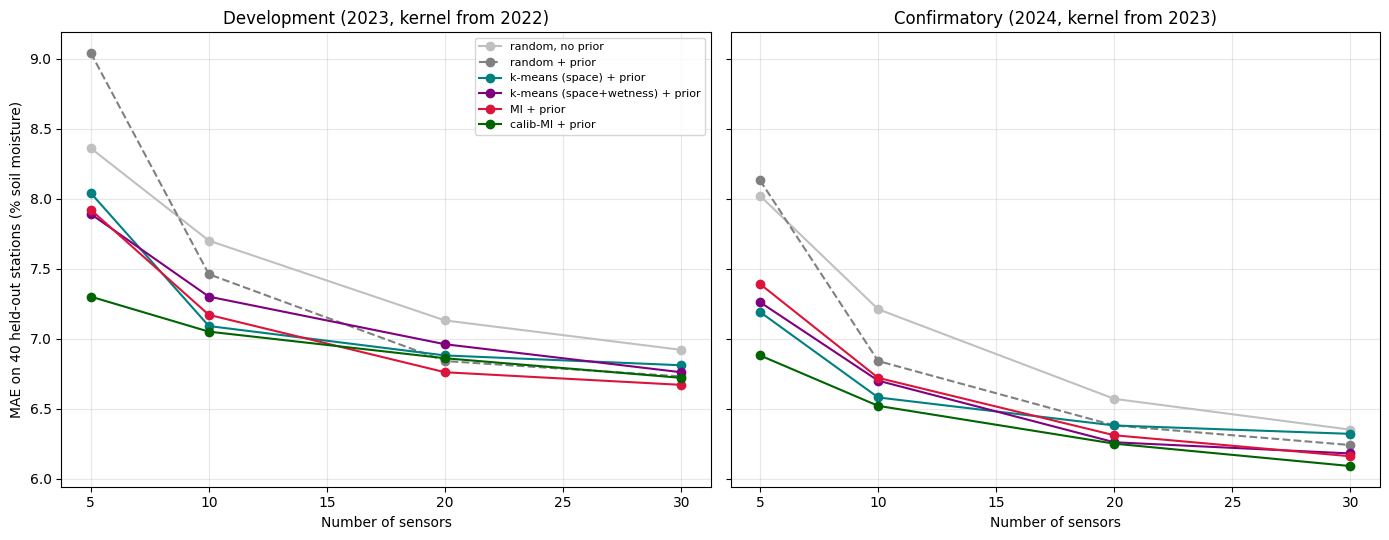

In [13]:
styles = {"random, no prior": ("silver", "-"), "random + prior": ("gray", "--"),
          "k-means (space) + prior": ("teal", "-"), "k-means (space+wetness) + prior": ("purple", "-"),
          "MI + prior": ("crimson", "-"), "calib-MI + prior": ("darkgreen", "-")}
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, st_, title in [(axes[0], dev_stats, "Development (2023, kernel from 2022)"),
                       (axes[1], conf_stats, "Confirmatory (2024, kernel from 2023)")]:
    for m in METHODS:
        c, ls = styles[m]
        ax.plot(COUNTS, [st_["mae"][str(n)][m] for n in COUNTS], marker="o", color=c, linestyle=ls, label=m)
    ax.set_title(title)
    ax.set_xlabel("Number of sensors")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("MAE on 40 held-out stations (% soil moisture)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig("results_figure.png", dpi=200)
plt.show()

## 7. Save results, kernels, snapshots and run metadata

In [14]:
def kernel_json(hk, source):
    k = hk["resid"]
    return {"source": source, "constant": float(k.k1.k1.constant_value),
            "length_scale": float(k.k1.k2.length_scale), "nu": float(k.k1.k2.nu),
            "noise": float(k.k2.noise_level), "resid_std": float(hk["s_resid"])}

# app uses June 2023 data -> kernel from June 2022
with open("historical_kernel.json", "w") as f:
    json.dump(kernel_json(dev["2023-06"]["hk"], "June 2022 residual kernel (sensor_placement_confirmatory.ipynb)"), f, indent=2)

results = {
    "source": "sensor_placement_confirmatory.ipynb - confirmatory 2024 evaluation (kernel from 2023)",
    "mae": conf_stats["mae"],
    "confirmatory": conf_stats,
    "development": dev_stats,
}
with open("experiment_results.json", "w") as f:
    json.dump(results, f, indent=2)

for res, tag in [(dev, "dev"), (conf, "confirm")]:
    for mo in res:
        RUN_INFO["months"][mo]["kernel_from_previous_year"] = res[mo]["kernel"]
        RUN_INFO["months"][mo]["test_sets_" + tag] = res[mo]["test_sets"]
RUN_INFO["run_finished_utc"] = datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z"
with open("run_metadata.json", "w") as f:
    json.dump(RUN_INFO, f, indent=1)

with zipfile.ZipFile("confirmatory_outputs.zip", "w") as z:
    for fn in ["experiment_results.json", "historical_kernel.json", "run_metadata.json", "results_figure.png"]:
        z.write(fn)
    for fn in sorted(os.listdir("snapshots")):
        z.write(os.path.join("snapshots", fn))
print("saved confirmatory_outputs.zip")

from google.colab import files
files.download("confirmatory_outputs.zip")

saved confirmatory_outputs.zip


/tmp/ipykernel_1229/3785646521.py:24: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  RUN_INFO["run_finished_utc"] = datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z"


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>